# Projeto Final — Análise Exploratória de um App de Delivery
### DS-PY-018 · Análise Exploratória de Dados

**Contexto:** vocês são o time de dados de um app de delivery de comida que opera em **São Paulo, Rio de Janeiro e Belo Horizonte**. A diretoria vai planejar 2025 e pediu um diagnóstico de 2024 antes da reunião de orçamento. Ela quer entender três frentes:

1. **Operação** — quando os pedidos acontecem, quanto tempo as entregas levam e o que atrasa uma entrega;
2. **Clientes** — quanto gastam, como avaliam e o que derruba a avaliação;
3. **Alavancas** — qual o efeito real dos **cupons** (inclusive da campanha *"Julho de cupons"*) e da **chuva** sobre o negócio.

A base `delivery_pedidos.csv` (8.058 pedidos, 18 colunas) veio direto do sistema, **sem nenhum tratamento**. Ela tem problemas de qualidade — encontrá-los faz parte do trabalho.

> A diretoria não quer tabelas. Quer **5 achados** confiáveis e **3 recomendações** defendidas com dados.

---

**Entregas:**
1. Este notebook **resolvido e executado do início ao fim** (Etapas 1 a 11), sem erros.
2. Um **repositório Git** contendo: o notebook, um `README.md` (use o `modelo_README.md` desta pasta), a pasta `saidas/` com a base limpa e a figura principal.
3. Uma **apresentação de 7 minutos** na última aula (5 achados + 3 recomendações + 1 limitação), seguida de perguntas.

**Regras:**
- Trabalho individual.
- O notebook precisa **rodar do início ao fim** (*Kernel → Restart & Run All*) com o CSV original em `../dados/` (ou no caminho indicado no README).
- **Toda decisão de limpeza é justificada**: o que foi feito, por quê, e quantas linhas foram afetadas. Nunca preencha um faltante "porque sim".
- Toda resposta numérica vem com **uma frase de interpretação**.

**Hipóteses obrigatórias (Etapa 9):**

| # | Hipótese de negócio | Variáveis |
|---|---|---|
| H1 | Em dias de chuva as entregas demoram mais | `chuva` × `tempo_entrega_min` |
| H2 | Pedidos com cupom têm ticket diferente dos pedidos sem cupom | `cupom` × `valor_pedido` |
| H3 | Quanto mais demorada a entrega, pior a avaliação | `tempo_entrega_min` × `avaliacao` |
| H4 | O ticket varia conforme o tipo de cozinha | `tipo_cozinha` × `valor_pedido` |
| H5 | A forma de pagamento depende da cidade (qui-quadrado de independência) | `cidade` × `forma_pagamento` |
| H6 | **Do grupo** — uma hipótese própria, formulada na Etapa 1 | à escolha |

**Prazo e apresentação:** o projeto é apresentado na **última aula do módulo**. Ordem das apresentações ordem alfabetica.

**Critérios de avaliação:** rubrica analítica em [`rubrica_avaliacao.md`](rubrica_avaliacao.md) — uso de DataFrames no Pandas · estatísticas descritivas · sumarização · cálculo de métricas · escolha de visualizações · estilização · validação de hipóteses · granularidade · publicação dos dados · tratamento de dados e reprodutibilidade · comunicação. Leiam a rubrica **antes** de começar: ela diz exatamente o que separa "Proficiente" de "Avançado".

### Dicionário de dados (como o sistema descreve as colunas)

| Coluna | Descrição |
|---|---|
| `pedido_id` | identificador do pedido |
| `data_hora` | data e hora do pedido (`AAAA-MM-DD HH:MM`) |
| `cidade`, `bairro` | local de entrega |
| `restaurante_id` | identificador do restaurante |
| `tipo_cozinha` | Pizza, Japonesa, Hambúrguer, Brasileira, Saudável, Doces |
| `plataforma` | Android, iOS ou Web |
| `forma_pagamento` | Cartão de crédito, Pix, Vale-refeição, Dinheiro |
| `cupom` | se o pedido usou cupom de desconto |
| `cliente_novo` | primeiro pedido do cliente no app |
| `chuva` | choveu na cidade naquele dia |
| `distancia_km` | distância restaurante → cliente |
| `tempo_entrega_min` | minutos entre o pedido e a entrega (o sistema grava `999` quando não há registro) |
| `valor_pedido` | valor dos itens, em R$ (sem a taxa) |
| `taxa_entrega` | taxa de entrega cobrada, em R$ |
| `avaliacao` | nota de 1 a 5 dada pelo cliente (opcional) |
| `pais`, `moeda` | país e moeda da transação |

> ⚠️ O dicionário diz o que a coluna **deveria** conter. A Etapa 2 é sobre descobrir o que ela **de fato** contém.

**Como usar este notebook:** cada etapa tem tarefas numeradas. Células `# Sua solução aqui` são código; células *Sua resposta aqui* são texto (interpretação, decisão ou justificativa). Células de código já preenchidas — como os **checkpoints** ✅ — não devem ser alteradas: se um checkpoint falhar, volte e revise a etapa.

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

sns.set_theme(style="whitegrid")
DADOS = "../dados/"

---
## Etapa 1 — Perguntas e hipóteses

> Na aula 6 vimos que a EDA começa **antes** do código: sem pergunta, qualquer gráfico parece interessante.

### Tarefa 1.1
Escrevam **5 perguntas de negócio** que a diretoria faria sobre esta base — pelo menos uma de cada frente (operação, clientes, alavancas). Para cada pergunta, indiquem **qual coluna (ou combinação) responde** e **em que granularidade** (pedido, dia, cidade-dia, mês...).

*Sua resposta aqui*

| Frente | Pergunta de negócio | Colunas usadas | Granularidade |
|---|---|---|---|
| Operação | Em quais combinações de dia da semana e horário se concentram mais pedidos e entregas mais demoradas? | `data_hora`, `pedido_id`, `tempo_entrega_min` | Dia da semana × hora |
| Clientes | Pedidos que demoram mais para chegar tendem a receber notas mais baixas? | `tempo_entrega_min`, `avaliacao` | Pedido |
| Operação e clientes | Os tipos de cozinha com entregas mais rápidas também têm as melhores avaliações? | `tipo_cozinha`, `tempo_entrega_min`, `avaliacao` | Tipo de cozinha |
| Alavancas | Qual é a diferença no valor médio entre pedidos com e sem cupom para clientes novos e para os demais? | `cupom`, `valor_pedido`, `cliente_novo` | Pedido, com comparação por perfil de cliente |
| Clientes | Pedidos com taxa de entrega mais alta tendem a receber notas mais baixas? | `taxa_entrega`, `avaliacao` | Pedido |

### Tarefa 1.2
Para cada hipótese obrigatória (H1–H5 do enunciado) escrevam **H0 e H1 estatísticas** e o **teste que pretendem usar**, justificando pelo tipo das variáveis. Depois formulem a **H6** — algo que vocês genuinamente não sabem a resposta.

*Sua resposta aqui*

| Hipótese de negócio | H₀ — Hipótese nula | H₁ — Hipótese alternativa | Teste e justificativa |
|---|---|---|---|
| **H1 — Chuva e tempo de entrega** | A distribuição dos tempos de entrega é igual nos pedidos com e sem chuva. | Os tempos de entrega tendem a ser maiores nos pedidos com chuva. | **Mann–Whitney unilateral.** Compara os tempos de dois grupos pela ordem dos valores. A hipótese indica uma direção. |
| **H2 — Cupom e valor do pedido** | A distribuição do valor dos pedidos é igual nos grupos com e sem cupom. | Os valores dos pedidos tendem a ser maiores em um dos dois grupos. | **Mann–Whitney bilateral.** Compara os valores dos pedidos entre dois grupos e considera diferenças nos dois sentidos. |
| **H3 — Tempo de entrega e avaliação** | A correlação de Spearman entre tempo e avaliação é zero. | A correlação é negativa. Pedidos mais demorados tendem a receber notas menores. | **Spearman unilateral.** O tempo é numérico, e as notas têm uma ordem. |
| **H4 — Tipo de cozinha e valor do pedido** | A distribuição do valor dos pedidos é igual em todos os tipos de cozinha. | Em pelo menos um tipo de cozinha, os valores tendem a ser maiores ou menores do que em outro. | **Kruskal–Wallis.** Compara os valores dos pedidos pela ordem dos valores entre mais de dois grupos. |
| **H5 — Cidade e forma de pagamento** | Cidade e forma de pagamento são independentes. | Existe associação entre cidade e forma de pagamento. | **Qui-quadrado de independência.** As duas variáveis são categóricas, então o teste compara as contagens observadas com as esperadas. |
| **H6 — Taxa de entrega e avaliação** | A correlação de Spearman entre taxa de entrega e avaliação é zero. | A correlação é negativa. Pedidos com taxas maiores tendem a receber notas menores. | **Spearman unilateral.** A taxa é numérica, e as notas têm uma ordem. |

---
## Etapa 2 — Carga e inspeção

> Ainda **não** mexa nos dados. Esta etapa é um inventário: o que veio, em que formato e com que problemas.

In [2]:
bruto = pd.read_csv(DADOS + "delivery_pedidos.csv")
bruto.shape

(8058, 18)

### Tarefa 2.1
Mostre as 5 primeiras linhas e o resultado de `info()`. Quantas linhas e colunas? Quanta memória a base ocupa?

In [3]:
# Sua solução aqui
display(bruto.head())
print("Linhas e colunas:", bruto.shape)
bruto.info(memory_usage="deep")

,pedido_id,data_hora,cidade,bairro,restaurante_id,tipo_cozinha,plataforma,forma_pagamento,cupom,cliente_novo,chuva,distancia_km,tempo_entrega_min,valor_pedido,taxa_entrega,avaliacao,pais,moeda
0,500000,2024-01-01 11:21,São Paulo,Tatuapé,R912,Hambúrguer,Android,Pix,Não,False,False,2.68,28,"R$ 44,02",7.40,4.0,Brasil,BRL
1,500001,2024-01-01 20:09,São Paulo,Tatuapé,R760,Hambúrguer,Android,Pix,Sim,False,False,3.28,37,45.54,7.94,5.0,Brasil,BRL
2,500002,2024-01-01 11:20,São Paulo,Santana,R760,Hambúrguer,Android,cartao credito,Não,False,False,3.19,30,92.28,7.86,5.0,Brasil,BRL
3,500003,2024-01-01 22:14,São Paulo,Moema,R338,Saudável,Android,Cartão de crédito,Sim,True,False,2.75,17,39.09,7.46,4.0,Brasil,BRL
4,500004,2024-01-01 12:50,São Paulo,Pinheiros,R169,Hambúrguer,Android,Pix,Não,False,False,1.63,24,74.2,6.46,5.0,Brasil,BRL


Linhas e colunas: (8058, 18)
<class 'pandas.DataFrame'>
RangeIndex: 8058 entries, 0 to 8057
Data columns (total 18 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   pedido_id          8058 non-null   int64  
 1   data_hora          8058 non-null   str    
 2   cidade             8058 non-null   str    
 3   bairro             8058 non-null   str    
 4   restaurante_id     8058 non-null   str    
 5   tipo_cozinha       8058 non-null   str    
 6   plataforma         7905 non-null   str    
 7   forma_pagamento    8058 non-null   str    
 8   cupom              8058 non-null   str    
 9   cliente_novo       8058 non-null   bool   
 10  chuva              8058 non-null   bool   
 11  distancia_km       7743 non-null   float64
 12  tempo_entrega_min  8058 non-null   int64  
 13  valor_pedido       8058 non-null   str    
 14  taxa_entrega       8058 non-null   float64
 15  avaliacao          6716 non-null   float64
 16  pais  

A base original tem 8.058 linhas e 18 colunas. Cada linha representa
um pedido. Usei `head()` para mostrar os cinco primeiros pedidos e
`info()` para conferir a estrutura da base, que ocupa 5,4 MB de memória.

Três colunas têm valores faltantes. São 153 em `plataforma`,
315 em `distancia_km` e 1.342 em `avaliacao`.

O pandas leu 11 colunas como texto, 2 como números inteiros,
3 como números decimais e 2 como booleanas. Entre as colunas
lidas como texto estão `data_hora` e `valor_pedido`, que serão
verificadas na próxima tarefa.

### Tarefa 2.2
Quais colunas vieram com o **tipo errado** para o que representam? Prove com código (dica: tente converter `valor_pedido` para número e veja o que acontece).

In [4]:
# Sua solução aqui
print(bruto[["data_hora", "cupom", "valor_pedido"]].dtypes)

valores = bruto["valor_pedido"]
teste = pd.to_numeric(valores, errors="coerce")
falhas = valores.notna() & teste.isna()

print("\nValores preenchidos que falharam na conversão:", falhas.sum())
print(valores[falhas].head())

data_hora       str
cupom           str
valor_pedido    str
dtype: object

Valores preenchidos que falharam na conversão: 720
0      R$ 44,02
18     R$ 36,08
28     R$ 35,49
33     R$ 60,70
39    R$ 105,27
Name: valor_pedido, dtype: str


*Sua resposta aqui*

As colunas `data_hora`, `cupom` e `valor_pedido` vieram como texto.
`data_hora` representa a data e o horário do pedido. `cupom` indica
se houve uso de cupom (`Sim` ou `Não`). `valor_pedido` representa
um valor em dinheiro.

Na tentativa de converter `valor_pedido` diretamente para número,
720 valores preenchidos falharam. Um exemplo é `R$ 44,02`.
As conversões serão feitas na etapa de limpeza dos dados.

### Tarefa 2.3
Calcule o número de valores distintos (`nunique`) de **todas** as colunas. Depois liste os valores de `cidade` e de `forma_pagamento`. Que problemas aparecem?

In [5]:
# Sua solução aqui
print("Quantidade de valores distintos por coluna")
print(bruto.nunique())

print("\nValores de cidade")
print(bruto["cidade"].unique().tolist())

print("\nValores de forma de pagamento")
print(bruto["forma_pagamento"].unique().tolist())

Quantidade de valores distintos por coluna
pedido_id            8058
data_hora            7913
cidade                 13
bairro                 15
restaurante_id        101
tipo_cozinha            6
plataforma              3
forma_pagamento         8
cupom                   2
cliente_novo            2
chuva                   2
distancia_km         1043
tempo_entrega_min      96
valor_pedido         5956
taxa_entrega          941
avaliacao               5
pais                    1
moeda                   1
dtype: int64

Valores de cidade
['São Paulo', 'Rio', 'Rio de Janeiro', 'Belo Horizonte', 'BH', 'SÃO PAULO', 'sao paulo', 'rio de janeiro', 'SP', 'São Paulo ', 'B. Horizonte', 'belo horizonte', 'RJ']

Valores de forma de pagamento
['Pix', 'cartao credito', 'Cartão de crédito', 'Vale-refeição', 'Dinheiro', 'dinheiro', 'PIX', 'VR']


*Sua resposta aqui*

### Tarefa 2.4
Monte uma tabela com a **quantidade e o percentual de faltantes** por coluna, só com as colunas que têm faltantes, ordenada do maior para o menor.

In [7]:
# Sua solução aqui
quantidade = bruto.isna().sum()

tabela_faltantes = pd.DataFrame({
    "Quantidade": quantidade,
    "Percentual (%)": (quantidade / len(bruto) * 100).round(2)
})

tabela_faltantes = tabela_faltantes[tabela_faltantes["Quantidade"] > 0]
tabela_faltantes.sort_values("Quantidade", ascending=False)

,Quantidade,Percentual (%)
avaliacao,1342,16.65
distancia_km,315,3.91
plataforma,153,1.90


Encontrei valores faltantes em três colunas. A coluna `avaliacao`
teve o maior percentual, com 1.342 pedidos sem nota (16,65%).
Em seguida vieram `distancia_km`, com 315 valores faltantes (3,91%),
e `plataforma`, com 153 (1,90%).

Os percentuais foram calculados sobre os 8.058 pedidos da base original.
Na limpeza dos dados, vou avaliar como tratar os faltantes de cada coluna.

### Tarefa 2.5
Rode `describe()` nas colunas numéricas e procure **valores impossíveis**. Conte quantos são em cada coluna suspeita.

In [8]:
# Sua solução aqui
display(bruto.select_dtypes(include="number").describe().T)

tempo = bruto["tempo_entrega_min"]
distancia = bruto["distancia_km"]

print("Tempos negativos:", (tempo < 0).sum())
print("Tempos iguais a 999 minutos:", (tempo == 999).sum())
print("Distâncias negativas:", (distancia < 0).sum())
print("Maior distância registrada (km):", distancia.max())

,count,mean,std,min,25%,50%,75%,max
pedido_id,8058.0,504028.500000,2326.288568,500000.00,502014.25,504028.50,506042.7500,508057.00
distancia_km,7743.0,3.797731,9.409026,0.08,1.77,3.03,4.7700,399.65
tempo_entrega_min,8058.0,38.848349,54.728561,-33.00,28.00,35.00,43.0000,999.00
taxa_entrega,8058.0,7.268727,3.285336,0.00,6.16,7.42,9.0775,26.94
avaliacao,6716.0,4.348868,0.685299,1.00,4.00,4.00,5.0000,5.00


Tempos negativos: 8
Tempos iguais a 999 minutos: 25
Distâncias negativas: 0
Maior distância registrada (km): 399.65


*Sua resposta aqui*

Encontrei 8 tempos de entrega negativos, que são impossíveis.
Também encontrei 25 registros com exatamente 999 minutos.
A repetição desse valor sugere que ele pode ser um código específico.
Ao todo, sinalizei 33 registros na coluna `tempo_entrega_min`.

Em `distancia_km`, não encontrei valores negativos. A maior
distância foi de 399,65 km, bem acima da mediana de 3,03 km.
Vou investigar esse valor na etapa de outliers antes de decidir
se precisa de correção.

### Tarefa 2.6
Existem linhas duplicadas? E `pedido_id` repetido?

In [9]:
# Sua solução aqui
linhas_duplicadas = bruto.duplicated().sum()
ids_repetidos = bruto["pedido_id"].duplicated().sum()

print("Linhas totalmente duplicadas:", linhas_duplicadas)
print("Registros com pedido_id repetido:", ids_repetidos)

Linhas totalmente duplicadas: 0
Registros com pedido_id repetido: 0


*Sua resposta aqui*

Na base original, encontrei 0 linhas totalmente duplicadas e
0 registros com `pedido_id` repetido. Os 8.058 registros têm
8.058 identificadores distintos, então não será necessário
remover linhas por duplicidade na etapa de limpeza.

### Tarefa 2.7 — Plano de limpeza
Antes de limpar, escreva uma tabela **problema | coluna | linhas afetadas | decisão planejada**. É o roteiro das Etapas 3 e 4.

*Sua resposta aqui*

| Problema | Coluna | Linhas afetadas | Decisão planejada |
|---|---|---:|---|
| Data e hora em texto | `data_hora` | 8.058 | Converter para data e hora. |
| Cupom em texto | `cupom` | 8.058 | Converter `Sim` para `True` e `Não` para `False`. |
| Valores em formatos diferentes | `valor_pedido` | 720 | Padronizar os valores e converter a coluna para número. |
| Nomes de cidades escritos de formas diferentes | `cidade` | 997 | Usar um nome padrão para cada uma das três cidades. |
| Formas de pagamento escritas de formas diferentes | `forma_pagamento` | 666 | Usar um nome padrão para cada uma das quatro formas de pagamento. |
| Colunas com um único valor | `pais` e `moeda` | 8.058 em cada coluna | Retirar essas colunas da cópia usada na análise. |
| Nota faltando | `avaliacao` | 1.342 | Verificar se as notas faltam mais em certos grupos e manter os valores ausentes (`NaN`). |
| Distância faltando | `distancia_km` | 315 | Manter como valor ausente (`NaN`). |
| Plataforma faltando | `plataforma` | 153 | Agrupar esses pedidos como `Não informada` nos resumos por plataforma. |
| Tempos negativos ou iguais a 999 minutos | `tempo_entrega_min` | 33 (8 negativos e 25 iguais a 999) | Marcar esses tempos como ausentes (`NaN`) e sinalizar os pedidos na coluna `tempo_invalido`. |
| Distâncias muito altas | `distancia_km` | A verificar na Etapa 4 | Investigar os casos, incluindo a distância de 399,65 km, antes de decidir se precisam de correção. |
| Linhas duplicadas ou IDs repetidos | Todas as colunas e `pedido_id` | 0 | Manter todos os pedidos. |

---
## Etapa 3 — Limpeza

Trabalhe numa cópia chamada **`df`**; `bruto` fica intacto para comparação. Use **exatamente** os nomes de colunas pedidos — o checkpoint no fim da etapa depende deles.

### Tarefa 3.1 — Colunas constantes
Detecte as colunas constantes **por código** (sem digitar o nome delas) e crie `df` sem elas.

In [10]:
# Sua solução aqui
valores_distintos = bruto.nunique(dropna=False)
colunas_constantes = valores_distintos[valores_distintos == 1].index

df = bruto.drop(columns=colunas_constantes).copy()

print("Colunas constantes:", colunas_constantes.tolist())
print("Base original:", bruto.shape)
print("Cópia para limpeza:", df.shape)

Colunas constantes: ['pais', 'moeda']
Base original: (8058, 18)
Cópia para limpeza: (8058, 16)


Usei `nunique()` para identificar as colunas com um único valor.
O código encontrou `pais` e `moeda`. Retirei essas duas colunas
da cópia `df` porque elas têm o mesmo valor em todos os pedidos.

A cópia ficou com 8.058 linhas e 16 colunas. A base original
`bruto` continua com 8.058 linhas e 18 colunas.

### Tarefa 3.2 — Datas
Converta `data_hora` para datetime e crie as colunas `data` (só o dia), `mes` (1–12), `hora` (0–23) e `dia_semana` (Seg, Ter, ..., Dom) **ordenada** como categoria. Qual o período coberto?

In [11]:
# Sua solução aqui
df["data_hora"] = pd.to_datetime(df["data_hora"], format="%Y-%m-%d %H:%M")

df["data"] = df["data_hora"].dt.date
df["mes"] = df["data_hora"].dt.month
df["hora"] = df["data_hora"].dt.hour

dias = ["Seg", "Ter", "Qua", "Qui", "Sex", "Sáb", "Dom"]
nomes_dias = dict(enumerate(dias))

df["dia_semana"] = pd.Categorical(
    df["data_hora"].dt.dayofweek.map(nomes_dias),
    categories=dias,
    ordered=True
)

display(df[["data_hora", "data", "mes", "hora", "dia_semana"]].head())

inicio = df["data_hora"].min()
fim = df["data_hora"].max()
print(f"Período coberto: {inicio:%d/%m/%Y %H:%M} a {fim:%d/%m/%Y %H:%M}")

,data_hora,data,mes,hora,dia_semana
0,2024-01-01 11:21:00,2024-01-01,1,11,Seg
1,2024-01-01 20:09:00,2024-01-01,1,20,Seg
2,2024-01-01 11:20:00,2024-01-01,1,11,Seg
3,2024-01-01 22:14:00,2024-01-01,1,22,Seg
4,2024-01-01 12:50:00,2024-01-01,1,12,Seg


Período coberto: 01/01/2024 11:11 a 31/12/2024 23:38


Converti `data_hora` para o tipo data e hora na cópia `df`.
A partir dela, criei `data` com a data sem o horário, `mes` com
o número do mês, `hora` com a hora do pedido e `dia_semana`
como categoria ordenada de segunda a domingo.

Os pedidos vão de 01/01/2024 às 11:11 até 31/12/2024 às 23:38.
Essas colunas vão ajudar a analisar os pedidos por mês, dia da
semana e horário.

### Tarefa 3.3 — Cidade
Padronize `cidade` para exatamente **3 valores**: `São Paulo`, `Rio de Janeiro`, `Belo Horizonte`. Mostre que nenhuma linha ficou sem cidade.

In [12]:
# Sua solução aqui
mapa_cidades = {
    "são paulo": "São Paulo",
    "sao paulo": "São Paulo",
    "sp": "São Paulo",
    "rio": "Rio de Janeiro",
    "rio de janeiro": "Rio de Janeiro",
    "rj": "Rio de Janeiro",
    "belo horizonte": "Belo Horizonte",
    "b. horizonte": "Belo Horizonte",
    "bh": "Belo Horizonte",
}

cidades = bruto["cidade"].str.strip().str.lower()
df["cidade"] = cidades.map(mapa_cidades)

print("Pedidos por cidade:")
print(df["cidade"].value_counts())

print("\nCidades distintas:", df["cidade"].nunique())
print("Pedidos sem cidade:", df["cidade"].isna().sum())

Pedidos por cidade:
cidade
São Paulo         4055
Rio de Janeiro    2371
Belo Horizonte    1632
Name: count, dtype: int64

Cidades distintas: 3
Pedidos sem cidade: 0


*Sua resposta aqui*

Padronizei os nomes da coluna `cidade` na cópia `df`. Retirei
espaços extras e reuni as grafias e siglas que representavam a
mesma cidade. Por exemplo, `SP` e `SÃO PAULO` ficaram como `São Paulo`.

A coluna passou de 13 grafias para três cidades: São Paulo,
Rio de Janeiro e Belo Horizonte. A conferência mostrou que
nenhum pedido ficou sem cidade.

### Tarefa 3.4 — Forma de pagamento
Padronize `forma_pagamento` para os 4 valores canônicos do dicionário.

In [13]:
# Sua solução aqui
mapa_pagamentos = {
    "pix": "Pix",
    "cartao credito": "Cartão de crédito",
    "cartão de crédito": "Cartão de crédito",
    "vale-refeição": "Vale-refeição",
    "vr": "Vale-refeição",
    "dinheiro": "Dinheiro",
}

pagamentos = bruto["forma_pagamento"].str.strip().str.lower()
df["forma_pagamento"] = pagamentos.map(mapa_pagamentos)

print(df["forma_pagamento"].value_counts())
print("\nFormas de pagamento distintas:", df["forma_pagamento"].nunique())
print("Pedidos sem forma de pagamento:", df["forma_pagamento"].isna().sum())

forma_pagamento
Cartão de crédito    3642
Pix                  2633
Vale-refeição        1222
Dinheiro              561
Name: count, dtype: int64

Formas de pagamento distintas: 4
Pedidos sem forma de pagamento: 0


Padronizei a coluna `forma_pagamento` na cópia `df`. Por exemplo,
`Pix` e `PIX` ficaram como `Pix`, e `VR` ficou como `Vale-refeição`.

A coluna passou de oito grafias para quatro formas de pagamento.
A conferência mostrou que nenhum pedido ficou sem essa informação.

### Tarefa 3.5 — Valor do pedido
Converta `valor_pedido` para número. Garanta que **nenhum** valor virou `NaN` na conversão (se virar, é sinal de que sua limpeza do texto falhou, não de que o dado é faltante).

In [14]:
# Sua solução aqui
valor = bruto["valor_pedido"].str.replace("R$", "", regex=False).str.strip()

# Ajusta os valores escritos com vírgula decimal
tem_virgula = valor.str.contains(",", regex=False, na=False)
valor.loc[tem_virgula] = (
    valor.loc[tem_virgula]
    .str.replace(".", "", regex=False)
    .str.replace(",", ".", regex=False)
)

valor_numerico = pd.to_numeric(valor, errors="coerce")
faltantes = valor_numerico.isna()

print("Valores ausentes após a conversão:", faltantes.sum())

if faltantes.any():
    print("Exemplos de valores que precisam de revisão:")
    print(bruto.loc[faltantes, "valor_pedido"].head())
    raise ValueError("Revise os valores antes de atualizar df.")

df["valor_pedido"] = valor_numerico
print("Tipo final:", df["valor_pedido"].dtype)

Valores ausentes após a conversão: 0
Tipo final: float64


*Sua resposta aqui*

Padronizei os formatos da coluna `valor_pedido` e converti os
valores para número na cópia `df`. Por exemplo, `R$ 44,02`
foi convertido para `44.02`.

A conversão direta tinha falhado em 720 valores. Depois da
padronização, os 8.058 valores foram convertidos e nenhum
ficou ausente (`NaN`).

### Tarefa 3.6 — Cupom
Converta `cupom` para booleano (`True`/`False`).

In [17]:
# Sua solução aqui
cupom_texto = bruto["cupom"].str.strip().str.lower()
cupom_booleano = cupom_texto.map({"sim": True, "não": False})

if cupom_booleano.isna().any():
    print(bruto.loc[cupom_booleano.isna(), "cupom"].unique())
    raise ValueError("Confira os valores de cupom antes de atualizar df.")

df["cupom"] = cupom_booleano.astype(bool)

print("Tipo final:", df["cupom"].dtype)
print(df["cupom"].value_counts(dropna=False))
contagem_cupom = df["cupom"].value_counts(dropna=False)
print("Total de pedidos:", contagem_cupom.sum())

Tipo final: bool
cupom
False    6349
True     1709
Name: count, dtype: int64
Total de pedidos: 8058


Converti a coluna `cupom` para o tipo booleano na cópia `df`.
Usei `True` para pedidos com cupom e `False` para pedidos sem cupom.
A conferência mostrou que os 8.058 pedidos ficaram com um desses
dois valores.

### Tarefa 3.7 — Faltantes
Decida o que fazer com os faltantes de `plataforma`, `avaliacao` e `distancia_km`. Antes de decidir sobre `avaliacao`, **investigue** se o faltante parece aleatório ou se depende de algo (cidade, cozinha, tempo de entrega...). Justifique cada decisão.

In [18]:
# Sua solução aqui
sem_nota = df["avaliacao"].isna()

# Separa os tempos em faixas, deixando os tempos inválidos fora da comparação.
tempo = df["tempo_entrega_min"]
tempo_valido = tempo.where((tempo > 0) & (tempo != 999))

faixa_tempo = pd.cut(
    tempo_valido,
    bins=[0, 35, 50, float("inf")],
    labels=["Até 35 min", "36 a 50 min", "Acima de 50 min"]
)

grupos = {
    "Cidade": df["cidade"],
    "Tipo de cozinha": df["tipo_cozinha"],
    "Faixa de tempo": faixa_tempo
}

for nome, grupo in grupos.items():
    resumo = sem_nota.groupby(grupo, observed=True).agg(
        pedidos="size",
        sem_avaliacao="sum"
    )
    resumo["percentual_sem_avaliacao"] = (
        resumo["sem_avaliacao"] / resumo["pedidos"] * 100
    ).round(2)

    print(nome)
    display(resumo)

# Cria uma categoria para os pedidos sem plataforma registrada.
df["plataforma"] = df["plataforma"].fillna("Não informada")

print("Pedidos com plataforma 'Não informada':",
      df["plataforma"].eq("Não informada").sum())

print("\nValores que continuam ausentes:")
print(df[["avaliacao", "distancia_km"]].isna().sum())

Cidade


,pedidos,sem_avaliacao,percentual_sem_avaliacao
cidade,,,
Belo Horizonte,1632,277,16.97
Rio de Janeiro,2371,401,16.91
São Paulo,4055,664,16.37


Tipo de cozinha


,pedidos,sem_avaliacao,percentual_sem_avaliacao
tipo_cozinha,,,
Brasileira,1561,248,15.89
Doces,814,145,17.81
Hambúrguer,1921,327,17.02
Japonesa,1116,183,16.40
Pizza,1786,287,16.07
Saudável,860,152,17.67


Faixa de tempo


,pedidos,sem_avaliacao,percentual_sem_avaliacao
tempo_entrega_min,,,
Até 35 min,4117,691,16.78
36 a 50 min,3112,519,16.68
Acima de 50 min,796,130,16.33


Pedidos com plataforma 'Não informada': 153

Valores que continuam ausentes:
avaliacao       1342
distancia_km     315
dtype: int64


*Sua resposta aqui*

Comparei o percentual de pedidos sem avaliação por cidade, tipo de
cozinha e faixa de tempo de entrega. As taxas foram próximas nos
grupos analisados. Por exemplo, por cidade, ficaram entre 16,37%
e 16,97%. Não encontrei uma concentração clara de notas faltantes
nesses grupos.

- `plataforma`: marquei os 153 casos faltantes como `Não informada`.
  Assim, esses pedidos aparecem na contagem por plataforma sem
  atribuir a eles uma plataforma que eu desconheço.
- `avaliacao`: mantive os 1.342 valores ausentes. Nas análises de
  nota, vou usar os pedidos que foram avaliados, pois preencher
  uma nota mudaria o resultado.
- `distancia_km`: mantive os 315 valores ausentes. Vou usar as
  distâncias registradas nas análises dessa medida, pois não
  tenho informação para recuperar as distâncias que faltam.

### ✅ Checkpoint da limpeza
Rode a célula abaixo **sem alterar**. Se algum `assert` falhar, a mensagem diz o que revisar.

In [20]:
assert {"pais", "moeda"}.isdisjoint(df.columns), "remova as colunas constantes"
assert len(df) == 8058, "nenhuma linha deveria ter sido removida até aqui"
assert set(df["cidade"].unique()) == {"São Paulo", "Rio de Janeiro", "Belo Horizonte"}, "cidade não padronizada"
assert set(df["forma_pagamento"].unique()) == {"Cartão de crédito", "Pix", "Vale-refeição", "Dinheiro"}, "pagamento não padronizado"
assert pd.api.types.is_numeric_dtype(df["valor_pedido"]) and df["valor_pedido"].notna().all(), "valor_pedido deve ser numérico e sem NaN"
assert pd.api.types.is_datetime64_any_dtype(df["data_hora"]), "data_hora deve ser datetime"
assert pd.api.types.is_bool_dtype(df["cupom"]), "cupom deve ser booleano"
assert df["plataforma"].notna().all(), "trate os faltantes de plataforma"
assert {"data", "mes", "hora", "dia_semana"}.issubset(df.columns), "crie as colunas de data"
print("Checkpoint da limpeza OK →", df.shape)

Checkpoint da limpeza OK → (8058, 20)


O checkpoint da limpeza passou. A base `df` ficou com 8.058 pedidos
e 20 colunas. Retirei duas colunas constantes e criei quatro colunas
a partir de `data_hora`. Todos os pedidos foram mantidos.

---
## Etapa 4 — Outliers: erro × extremo legítimo

> A pergunta nunca é "é outlier?". É **"é erro ou é real?"**. Erro se corrige ou se descarta; extremo real se **mantém** e se trata com estatística robusta.

### Tarefa 4.1 — Tempo de entrega
Visualize a distribuição de `tempo_entrega_min` com um boxplot. Trate os códigos `999` e os negativos: transforme-os em `NaN` e crie a flag `tempo_invalido`. Mostre a distribuição depois do tratamento.

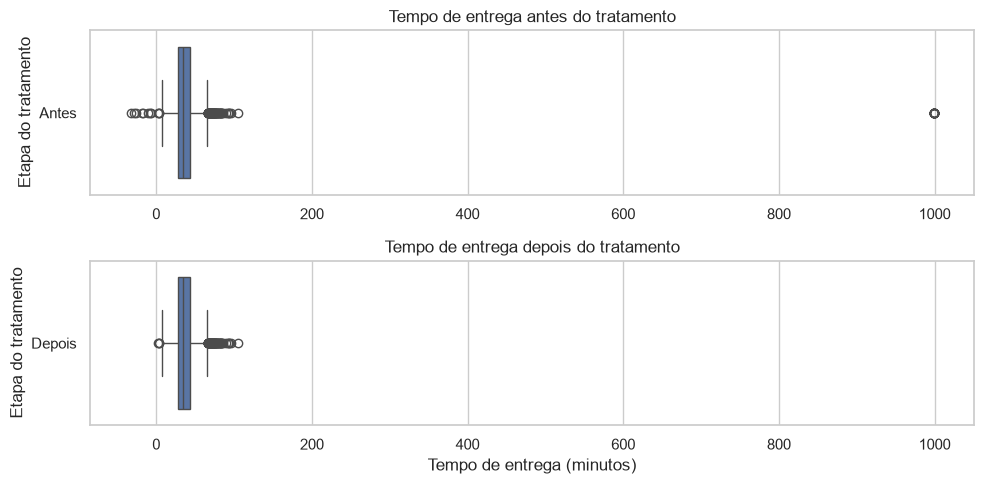

Tempos negativos: 8
Tempos iguais a 999 minutos: 25
Pedidos marcados como tempo inválido: 33
Pedidos com tempo válido: 8025
Total de pedidos: 8058


In [22]:
# Sua solução aqui
tempo_original = bruto["tempo_entrega_min"]

# Marca os tempos inválidos e substitui apenas esses valores por NaN.
df["tempo_invalido"] = (tempo_original < 0) | (tempo_original == 999)
df["tempo_entrega_min"] = tempo_original.mask(df["tempo_invalido"])

# Usa a mesma escala horizontal nos dois gráficos.
fig, eixos = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

sns.boxplot(x=tempo_original, ax=eixos[0])
eixos[0].set_title("Tempo de entrega antes do tratamento")
eixos[0].set_xlabel("Tempo de entrega (minutos)")
eixos[0].set_ylabel("Etapa do tratamento")
eixos[0].set_yticks([0], labels=["Antes"])
eixos[0].tick_params(axis="x", labelbottom=True)

sns.boxplot(x=df["tempo_entrega_min"].dropna(), ax=eixos[1])
eixos[1].set_title("Tempo de entrega depois do tratamento")
eixos[1].set_xlabel("Tempo de entrega (minutos)")
eixos[1].set_ylabel("Etapa do tratamento")
eixos[1].set_yticks([0], labels=["Depois"])

plt.tight_layout()
plt.show()

print("Tempos negativos:", (tempo_original < 0).sum())
print("Tempos iguais a 999 minutos:", (tempo_original == 999).sum())
print("Pedidos marcados como tempo inválido:", df["tempo_invalido"].sum())
print("Pedidos com tempo válido:", df["tempo_entrega_min"].notna().sum())
print("Total de pedidos:", len(df))

*Sua resposta aqui*

Comparei os tempos de entrega antes e depois do tratamento usando
dois boxplots na mesma escala.

Encontrei 33 tempos inválidos, sendo 8 negativos e 25 iguais a
999 minutos. Substituí esses tempos por `NaN` e marquei os pedidos
afetados com `True` na coluna `tempo_invalido`.

Mantive os 8.058 pedidos na base. Depois do tratamento, 8.025
pedidos ficaram com tempo de entrega válido.

### Tarefa 4.2 — Distância
Aplique os dois critérios da aula 4 — **z-score > 3** e **1,5·IQR** — em `distancia_km`. Quantos pedidos cada um sinaliza? Olhe os maiores valores: onde está a fronteira entre "longe" e "impossível"? Trate e crie a flag `distancia_invalida`.

In [25]:
# Sua solução aqui
distancia = bruto["distancia_km"]

# Z-score: distância em relação à média, em desvios padrão
media = distancia.mean()
desvio = distancia.std(ddof=0)
z_score = (distancia - media) / desvio
fora_z = z_score > 3

# IQR: amplitude da metade central das distâncias
q1 = distancia.quantile(0.25)
q3 = distancia.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

fora_iqr = (distancia < limite_inferior) | (distancia > limite_superior)

print(f"Corte do z-score: {media + 3 * desvio:.2f} km")
print("Pedidos sinalizados pelo z-score:", fora_z.sum())
print(f"Limites do IQR: {limite_inferior:.2f} a {limite_superior:.2f} km")
print("Pedidos sinalizados pelo IQR:", fora_iqr.sum())

print("\nDez maiores distâncias:")
display(
    bruto[["pedido_id", "distancia_km"]].nlargest(10, "distancia_km")
)

# Trata as distâncias acima do corte escolhido para esta base.
df["distancia_invalida"] = distancia > 100
df["distancia_km"] = distancia.mask(df["distancia_invalida"])

print("Distâncias marcadas como inválidas:", df["distancia_invalida"].sum())
print("Distâncias ausentes antes:", distancia.isna().sum())
print("Distâncias ausentes depois:", df["distancia_km"].isna().sum())
print("Total de pedidos:", len(df))

Corte do z-score: 32.02 km
Pedidos sinalizados pelo z-score: 7
Limites do IQR: -2.73 a 9.27 km
Pedidos sinalizados pelo IQR: 194

Dez maiores distâncias:


,pedido_id,distancia_km
3242,503242,399.65
706,500706,391.89
3926,503926,369.22
1539,501539,300.21
5826,505826,252.99
5749,505749,163.23
7133,507133,160.26
5200,505200,24.39
6687,506687,18.58
8003,508003,18.30


Distâncias marcadas como inválidas: 7
Distâncias ausentes antes: 315
Distâncias ausentes depois: 322
Total de pedidos: 8058


*Sua resposta aqui*

O z-score acima de 3 sinalizou 7 pedidos. O critério de 1,5 × IQR
sinalizou 194 pedidos, todos com distância acima de 9,27 km.

Ao ordenar as maiores distâncias, observei um salto de 24,39 km para
160,26 km. Dessa forma, distâncias de mais de 100 km são incompatíveis com entregas com o cenário de entregas urbanas. Mantive as distâncias longas até
24,39 km e marquei os 7 casos acima de 100 km em `distancia_invalida`.

Troquei essas 7 distâncias por `NaN`. A coluna passou de 315 para
322 valores ausentes, e os 8.058 pedidos foram mantidos na base.

### Tarefa 4.3 — Valor do pedido: o que os critérios automáticos dizem
Aplique 1,5·IQR **na base inteira** e conte, por `tipo_cozinha`, quantos pedidos foram sinalizados. Depois aplique o IQR **dentro de cada cozinha** e o z-score > 3. O que muda?

In [26]:
# Sua solução aqui
valor = df["valor_pedido"]
cozinha = df["tipo_cozinha"]

# 1. IQR da base inteira: os mesmos limites para todos os pedidos
q1 = valor.quantile(0.25)
q3 = valor.quantile(0.75)
iqr = q3 - q1

limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
fora_iqr_geral = (valor < limite_inferior) | (valor > limite_superior)

# 2. IQR por cozinha: cada pedido usa os limites da sua categoria
valores_por_cozinha = valor.groupby(cozinha)
q1_cozinha = valores_por_cozinha.transform("quantile", 0.25)
q3_cozinha = valores_por_cozinha.transform("quantile", 0.75)
iqr_cozinha = q3_cozinha - q1_cozinha

fora_iqr_cozinha = (
    (valor < q1_cozinha - 1.5 * iqr_cozinha)
    | (valor > q3_cozinha + 1.5 * iqr_cozinha)
)

# 3. Z-score da base inteira: mais de 3 desvios padrão acima da média
z_score = (valor - valor.mean()) / valor.std(ddof=0)
fora_z_score = z_score > 3

sinalizados = pd.DataFrame({
    "IQR geral": fora_iqr_geral,
    "IQR por cozinha": fora_iqr_cozinha,
    "Z-score > 3 (geral)": fora_z_score
})

resumo = sinalizados.groupby(cozinha).sum()
resumo.loc["Total"] = resumo.sum()

print(f"Limite superior do IQR geral: R$ {limite_superior:.2f}")
display(resumo)

Limite superior do IQR geral: R$ 144.97


,IQR geral,IQR por cozinha,Z-score > 3 (geral)
tipo_cozinha,,,
Brasileira,6,38,5
Doces,3,18,2
Hambúrguer,19,43,4
Japonesa,246,24,12
Pizza,70,60,4
Saudável,8,31,4
Total,352,214,31


*Sua resposta aqui*

#### O que mudou entre os critérios?

Primeiro, apliquei o IQR na base inteira. O limite superior foi de
R$ 144,97 para todas as cozinhas. Com essa regra, foram sinalizados
352 pedidos, sendo 246 da cozinha japonesa.

Depois, calculei o IQR separadamente para cada cozinha. Assim, cada
pedido foi comparado com os da sua própria categoria. Na cozinha
japonesa, a contagem caiu de 246 para 24. Na brasileira, subiu de 6
para 38. Isso mostra que um valor alto para o aplicativo como um
todo pode ser comum dentro de uma cozinha, e o contrário também
pode acontecer.

Por exemplo, um pedido japonês de R$ 150 seria sinalizado pelo IQR
geral, pois passa de R$ 144,97. No IQR por cozinha, o resultado
depende do limite calculado só para os pedidos japoneses.

Por fim, o z-score calculado na base inteira sinalizou 31 pedidos,
sendo 12 da cozinha japonesa. Essa regra marca valores que ficam
mais de três desvios padrão acima da média geral.

Um mesmo pedido pode ser sinalizado por mais de um critério.
Usei essas regras para identificar valores que merecem investigação
antes de decidir se precisam de correção.

### Tarefa 4.4 — Erro ou pedido corporativo?
Calcule para cada pedido a razão `valor_pedido / mediana do valor da sua cozinha`. Ordene as maiores razões e procure um **salto**. Examine os pedidos acima desse salto (cidade, data, cozinha, distância, taxa, tempo): eles parecem erro de digitação ou pedidos reais e grandes? Crie a flag `pedido_grande`.

In [31]:
# Sua solução aqui
mediana_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].transform("median")
razao_valor = df["valor_pedido"] / mediana_cozinha

maiores_razoes = pd.DataFrame({
    "tipo_cozinha": df["tipo_cozinha"],
    "valor_pedido": df["valor_pedido"],
    "mediana_cozinha": mediana_cozinha,
    "razao_valor": razao_valor
}).sort_values("razao_valor", ascending=False)

display(maiores_razoes.head(30).round(2))

,tipo_cozinha,valor_pedido,mediana_cozinha,razao_valor
6904,Pizza,2299.10,74.31,30.94
3553,Japonesa,2207.79,107.97,20.45
4023,Pizza,1441.97,74.31,19.41
6787,Hambúrguer,1071.77,61.67,17.38
491,Pizza,1035.26,74.31,13.93
3246,Doces,505.64,38.42,13.16
1035,Japonesa,1394.73,107.97,12.92
1263,Brasileira,614.31,47.82,12.85
1736,Hambúrguer,700.91,61.67,11.37
4045,Hambúrguer,625.71,61.67,10.15


In [35]:
df["pedido_grande"] = razao_valor > 4

colunas = [
    "pedido_id", "cidade", "data_hora", "tipo_cozinha", "valor_pedido",
    "distancia_km", "taxa_entrega", "tempo_entrega_min"
]

pedidos_grandes = (
    df.loc[df["pedido_grande"], colunas]
    .assign(razao_valor=razao_valor[df["pedido_grande"]])
    .sort_values("razao_valor", ascending=False)
)

display(pedidos_grandes.round({
    "valor_pedido": 2,
    "distancia_km": 2,
    "taxa_entrega": 2,
    "razao_valor": 2
}))
print("Pedidos marcados como grandes:", df["pedido_grande"].sum())
print("Total de pedidos na base:", len(df))

,pedido_id,cidade,data_hora,tipo_cozinha,valor_pedido,distancia_km,taxa_entrega,tempo_entrega_min,razao_valor
6904,506904,Rio de Janeiro,2024-11-17 11:07:00,Pizza,2299.10,2.03,6.82,25.0,30.94
3553,503553,São Paulo,2024-06-24 19:48:00,Japonesa,2207.79,0.89,5.79,18.0,20.45
4023,504023,São Paulo,2024-07-14 12:46:00,Pizza,1441.97,0.76,0.00,27.0,19.41
6787,506787,Rio de Janeiro,2024-11-12 17:33:00,Hambúrguer,1071.77,2.60,7.33,24.0,17.38
491,500491,São Paulo,2024-01-24 20:59:00,Pizza,1035.26,2.13,6.91,34.0,13.93
3246,503246,São Paulo,2024-06-09 20:38:00,Doces,505.64,1.30,0.00,29.0,13.16
1035,501035,São Paulo,2024-02-23 19:48:00,Japonesa,1394.73,2.35,7.10,39.0,12.92
1263,501263,São Paulo,2024-03-04 12:43:00,Brasileira,614.31,4.75,9.27,51.0,12.85
1736,501736,Rio de Janeiro,2024-03-27 14:45:00,Hambúrguer,700.91,11.92,15.72,59.0,11.37
4045,504045,São Paulo,2024-07-15 12:21:00,Hambúrguer,625.71,1.04,5.93,24.0,10.15


Pedidos marcados como grandes: 26
Total de pedidos na base: 8058


*Sua resposta aqui*

Dividi o valor de cada pedido pela mediana do seu tipo de cozinha.
Ao ordenar as razões, observei uma queda de 4,28 para 3,35 entre
o 26º e o 27º pedido. Usei 4 vezes a mediana como corte e marquei
26 pedidos com `True` na coluna `pedido_grande`.

Os pedidos marcados aparecem em cidades, datas e cozinhas diferentes.
Por exemplo, um pedido de pizza de R$ 2.299,10 teve distância de
2,03 km, taxa de R$ 6,82 e tempo de entrega de 25 minutos.

Como vários registros têm informações de entrega plausíveis,
mantive os valores e sinalizei os pedidos como grandes. A base
não tem informação suficiente para confirmar se eram corporativos.

### Tarefa 4.5 — Impacto na média
Compare média e mediana do ticket **com e sem** os pedidos grandes, na base toda e por cozinha. Qual métrica vocês vão usar para "ticket típico" daqui em diante?

In [36]:
# Sua solução aqui
sem_grandes = df.loc[~df["pedido_grande"]]

# Comparação na base toda
resumo_geral = pd.DataFrame({
    "Com pedidos grandes": df["valor_pedido"].agg(["mean", "median"]),
    "Sem pedidos grandes": sem_grandes["valor_pedido"].agg(["mean", "median"])
}).rename(index={"mean": "Média", "median": "Mediana"})

print("Ticket na base toda (R$)")
display(resumo_geral.round(2))

# Comparação por tipo de cozinha
com_por_cozinha = df.groupby("tipo_cozinha")["valor_pedido"].agg(
    media_com="mean",
    mediana_com="median"
)

sem_por_cozinha = sem_grandes.groupby("tipo_cozinha")["valor_pedido"].agg(
    media_sem="mean",
    mediana_sem="median"
)

print("Ticket por tipo de cozinha (R$)")
display(com_por_cozinha.join(sem_por_cozinha).round(2))

Ticket na base toda (R$)


,Com pedidos grandes,Sem pedidos grandes
Média,71.55,69.37
Mediana,61.61,61.48


Ticket por tipo de cozinha (R$)


,media_com,mediana_com,media_sem,mediana_sem
tipo_cozinha,,,,
Brasileira,51.17,47.82,49.94,47.75
Doces,41.79,38.42,40.64,38.40
Hambúrguer,67.65,61.67,66.25,61.61
Japonesa,120.37,107.97,115.38,107.73
Pizza,82.79,74.31,79.91,74.28
Saudável,58.77,53.74,57.22,53.46


*Sua resposta aqui*

Comparei o ticket com todos os pedidos e depois filtrei os 26 pedidos
marcados como grandes para medir o impacto deles. Na base toda, a
média caiu de R$ 71,55 para R$ 69,37. A mediana mudou de R$ 61,61
para R$ 61,48.

Na cozinha japonesa, a média caiu de R$ 120,37 para R$ 115,38,
enquanto a mediana mudou de R$ 107,97 para R$ 107,73.

Vou usar a mediana para representar o ticket típico, pois ela variou
menos com a presença dos pedidos grandes. Mantive esses pedidos na
base e usei o filtro apenas para esta comparação.

In [37]:
# ✅ Checkpoint dos outliers
assert df["tempo_entrega_min"].dropna().min() >= 0 and df["tempo_entrega_min"].max() < 999, "trate 999 e negativos"
assert df["distancia_km"].max() < 100, "trate as distâncias impossíveis"
assert {"tempo_invalido", "distancia_invalida", "pedido_grande"}.issubset(df.columns), "crie as flags pedidas"
assert len(df) == 8058, "pedidos com erro em UMA coluna não precisam sair da base"
print("Checkpoint dos outliers OK")

Checkpoint dos outliers OK


O checkpoint de outliers passou. Marquei 33 tempos de entrega e
7 distâncias como inválidos e substituí esses valores por `NaN`.
Mantive os 26 pedidos grandes na base e usei `pedido_grande` para
identificá-los. A base continua com 8.058 pedidos.

Vou usar a mediana como ticket típico, pois ela mudou menos que
a média quando comparei os resultados com e sem os pedidos grandes.

---
## Etapa 5 — Estatística descritiva

### Tarefa 5.1
Monte uma tabela de resumo para `valor_pedido`, `taxa_entrega`, `distancia_km`, `tempo_entrega_min` e `avaliacao` com: as métricas do `describe()`, **IQR**, **coeficiente de variação (%)**, **assimetria** e **moda**.

In [38]:
# Sua solução aqui
colunas = [
    "valor_pedido",
    "taxa_entrega",
    "distancia_km",
    "tempo_entrega_min",
    "avaliacao"
]

dados = df[colunas]
resumo = dados.describe().T

resumo["IQR"] = resumo["75%"] - resumo["25%"]
resumo["CV (%)"] = 100 * resumo["std"] / resumo["mean"]
resumo["Assimetria"] = dados.skew()

# Se houver empate, mostra todos os valores mais frequentes.
resumo["Moda"] = [
    ", ".join(f"{valor:g}" for valor in dados[coluna].mode())
    for coluna in colunas
]

resumo = resumo.rename(columns={
    "count": "Preenchidos",
    "mean": "Média",
    "std": "Desvio padrão",
    "min": "Mínimo",
    "50%": "Mediana",
    "max": "Máximo"
})

resumo["Preenchidos"] = resumo["Preenchidos"].astype(int)
display(resumo.round(2))

,Preenchidos,Média,Desvio padrão,Mínimo,25%,Mediana,75%,Máximo,IQR,CV (%),Assimetria,Moda
valor_pedido,8058,71.55,60.26,11.03,45.22,61.61,85.12,2299.10,39.90,84.22,17.52,"48.52, 104.62"
taxa_entrega,8058,7.27,3.29,0.00,6.16,7.42,9.08,26.94,2.92,45.20,-0.51,0
distancia_km,7736,3.54,2.39,0.08,1.77,3.02,4.76,24.39,2.99,67.55,1.37,2.7
tempo_entrega_min,8025,35.91,11.10,2.00,28.00,35.00,43.00,105.00,15.00,30.92,0.52,34
avaliacao,6716,4.35,0.69,1.00,4.00,4.00,5.00,5.00,1.00,15.76,-0.70,5


Resumi as cinco variáveis numéricas usando a base tratada. A tabela
mostra quantos valores estavam preenchidos, onde os valores se
concentram e quanto eles variam.

Usei o IQR para medir a largura da faixa central dos valores e o
coeficiente de variação para comparar a dispersão em relação à média.
A assimetria ajuda a ver se há uma cauda de valores altos ou baixos,
e a moda mostra quais valores aparecem com maior frequência.

No valor do pedido, a média ficou em R$ 71,55 e a mediana em R$ 61,61.
Vou usar a mediana como referência de ticket típico, pois na Tarefa 4.5
ela variou menos com a presença dos pedidos grandes.

### Tarefa 5.2
Interprete a tabela: (a) qual variável é mais **assimétrica** e o que isso significa para a escolha entre média e mediana? (b) qual tem **maior variabilidade relativa**? (c) o que a **moda** da `taxa_entrega` revela? (d) a avaliação média é alta ou baixa?

*Sua resposta aqui*

**(a) Variável mais assimétrica.** O `valor_pedido` teve a maior
assimetria em valor absoluto (17,52). A assimetria positiva indica
uma cauda à direita, formada pelos pedidos de valor muito alto.
Esses pedidos puxam a média para R$ 71,55, acima da mediana de
R$ 61,61. Por isso, vou usar a mediana como ticket típico.

**(b) Maior variabilidade relativa.** O `valor_pedido` também teve
o maior coeficiente de variação (84,22%). Isso significa que o
desvio padrão equivale a cerca de 84% da média. Entre as cinco
variáveis, o valor do pedido foi o que mais variou em relação
à própria média.

**(c) Moda da taxa de entrega.** A moda foi R$ 0,00, registrada
em 900 pedidos. Isso mostra que a taxa zero foi o valor mais
frequente. Como a mediana foi R$ 7,42, a taxa zero foi a mais
comum entre os valores individuais, mas esteve longe de ser
a taxa da maioria dos pedidos.

**(d) Avaliação média.** A média foi de 4,35 em uma escala de
1 a 5, então é alta. Esse resultado considera os 6.716 pedidos
com nota. Os 1.342 pedidos sem avaliação ficaram fora do cálculo.

### Tarefa 5.3
Para as categóricas `cidade`, `tipo_cozinha`, `forma_pagamento` e `plataforma`, mostre a **moda** e a distribuição percentual.

In [39]:
# Sua solução aqui
colunas_categoricas = ["cidade", "tipo_cozinha", "forma_pagamento", "plataforma"]

for coluna in colunas_categoricas:
    contagem = df[coluna].value_counts(dropna=False)
    percentual = 100 * contagem / contagem.sum()
    modas = contagem[contagem == contagem.max()].index.tolist()

    tabela = pd.DataFrame({
        "Quantidade de pedidos": contagem,
        "Percentual (%)": percentual.round(2)
    }).rename_axis(coluna)

    print(f"\n{coluna}")
    print("Moda:", ", ".join(map(str, modas)))
    display(tabela)


cidade
Moda: São Paulo


,Quantidade de pedidos,Percentual (%)
cidade,,
São Paulo,4055,50.32
Rio de Janeiro,2371,29.42
Belo Horizonte,1632,20.25



tipo_cozinha
Moda: Hambúrguer


,Quantidade de pedidos,Percentual (%)
tipo_cozinha,,
Hambúrguer,1921,23.84
Pizza,1786,22.16
Brasileira,1561,19.37
Japonesa,1116,13.85
Saudável,860,10.67
Doces,814,10.10



forma_pagamento
Moda: Cartão de crédito


,Quantidade de pedidos,Percentual (%)
forma_pagamento,,
Cartão de crédito,3642,45.20
Pix,2633,32.68
Vale-refeição,1222,15.17
Dinheiro,561,6.96



plataforma
Moda: Android


,Quantidade de pedidos,Percentual (%)
plataforma,,
Android,4449,55.21
iOS,2574,31.94
Web,882,10.95
Não informada,153,1.90


*Sua resposta aqui*

Calculei a distribuição percentual de cidade, tipo de cozinha,
forma de pagamento e plataforma. Em cada tabela, a moda é a
categoria com a maior quantidade de pedidos.

- **Cidade:** [moda], com [percentual]% dos pedidos.
- **Tipo de cozinha:** [moda], com [percentual]% dos pedidos.
- **Forma de pagamento:** [moda], com [percentual]% dos pedidos.
- **Plataforma:** [moda], com [percentual]% dos pedidos.

Na distribuição por plataforma, 153 pedidos (1,90%) ficaram
na categoria `Não informada`, pois o registro original não
indicava por onde o pedido foi feito.

### Tarefa 5.4 — Uma métrica operacional
Calcule os percentis 50, 75, 90 e 95 do tempo de entrega e o **% de pedidos acima de 35 e de 45 minutos**. Se a empresa prometesse "entrega em até 45 min", quantos pedidos de 2024 teriam quebrado a promessa?

In [41]:
# Sua solução aqui
tempos = df["tempo_entrega_min"].dropna()

percentis = tempos.quantile([0.50, 0.75, 0.90, 0.95])
percentis.index = ["P50", "P75", "P90", "P95"]

display(percentis.to_frame("Tempo de entrega (min)"))

limites = [35, 45]
quantidades = [(tempos > limite).sum() for limite in limites]

resumo_prazos = pd.DataFrame({
    "Acima de (min)": limites,
    "Quantidade de pedidos": quantidades,
    "Percentual (%)": [round(100 * n / len(tempos), 2) for n in quantidades]
})

print("Pedidos com tempo válido:", len(tempos))
display(resumo_prazos)

,Tempo de entrega (min)
P50,35.0
P75,43.0
P90,50.0
P95,55.0


Pedidos com tempo válido: 8025


,Acima de (min),Quantidade de pedidos,Percentual (%)
0,35,3908,48.70
1,45,1476,18.39


*Sua resposta aqui*

O tempo mediano de entrega foi de 35 minutos. Os percentis 75, 90
e 95 foram de 43, 50 e 55 minutos, respectivamente. Isso significa,
por exemplo, que cerca de 90% dos pedidos com tempo válido chegaram
em até 50 minutos.

Dos 8.025 pedidos com tempo válido, 3.908 (48,70%) passaram de
35 minutos. Se o prazo prometido fosse de até 45 minutos, 1.476
pedidos (18,39%) teriam ultrapassado esse prazo em 2024.

Os 33 pedidos com tempo inválido ficaram fora dessa comparação.

---
## Etapa 6 — Sumarização, métricas e granularidade

> Na aula 2: **granularidade** é o "nível de zoom" do dado. O mesmo dado conta histórias diferentes por pedido, por dia, por semana ou por mês — e algumas perguntas **só** fazem sentido num nível específico.

### Tarefa 6.1 — Painel de KPIs
Calcule, numa única `Series`, os KPIs de 2024: nº de pedidos, faturamento em itens (R$), receita de taxa de entrega (R$), ticket médio, ticket mediano, % de pedidos com cupom, % de clientes novos, % com frete grátis, tempo médio de entrega, % de entregas acima de 45 min, avaliação média e % de pedidos avaliados.

In [ ]:
# Sua solução aqui


### Tarefa 6.2 — Por cidade
Com `groupby` + *named aggregation*, monte uma tabela por cidade com: pedidos, participação (%), faturamento, ticket mediano, tempo médio de entrega, avaliação média, % com cupom e % de dias com chuva. Ordene por pedidos.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.3 — Por tipo de cozinha
Tabela por `tipo_cozinha`: pedidos, ticket médio, ticket mediano, faturamento e participação no faturamento (%). Qual cozinha tem o maior ticket? E o menor? A ordem por **volume** é a mesma da ordem por **faturamento**?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.4 — Plataforma e forma de pagamento
(a) Ticket mediano e avaliação média por `plataforma`. (b) Uma tabela cruzada `cidade × forma_pagamento` em **percentual por linha**. As cidades pagam de forma diferente?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.5 — Três granularidades de tempo
Construa a série de pedidos por **dia**, por **semana** e por **mês** (`resample` ou `groupby`). Para cada uma, responda: o que ela mostra que as outras escondem? Há algum dia anômalo? Há alguma semana que **não deve** ser comparada com as outras?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.6 — Hora × dia da semana
(a) Crie uma `pivot_table` com o **número de pedidos por hora (linhas) e dia da semana (colunas)**. (b) Calcule a **média de pedidos por dia** para cada dia da semana. Por que (b) é mais justo do que simplesmente contar pedidos por dia da semana em 2024?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.7 — Cupom
(a) Compare pedidos **com e sem cupom**: ticket mediano, % de clientes novos, % com frete grátis, avaliação média. (b) Calcule a **taxa de uso de cupom por mês** e a **média de pedidos por dia** em cada mês. O que aconteceu em julho?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.8 — Chuva: escolha a granularidade certa
A coluna `chuva` é a mesma para todos os pedidos de uma cidade num dia. (a) Calcule o **tempo médio de entrega** com e sem chuva. (b) Calcule a **média de pedidos por cidade-dia** com e sem chuva, por cidade. Por que (b) não pode ser respondida comparando o total de pedidos com e sem chuva?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 6.9 — Crescimento
O volume cresceu ao longo de 2024? Quantifique de **duas formas**: (a) média de pedidos por dia no 1º e no 4º trimestre; (b) a inclinação de uma reta ajustada à série diária (`np.polyfit`), expressa como crescimento % de janeiro a dezembro. Exclua da reta o dia anômalo 14/08.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

---
## Etapa 7 — Visualizações estilizadas

> Na aula 3: o gráfico certo responde **uma** pergunta, e o título diz **a resposta**. Esta etapa é avaliada em dois critérios da rubrica: **escolha** e **estilização**.

Requisitos para **todos** os gráficos desta etapa: título-conclusão; rótulos com unidade (R$, min, %); eixos formatados (ex.: `R$ 50`, não `50.0`); ordenação com sentido; paleta consistente (a mesma cor significa a mesma coisa em todos os gráficos); destaque para o que importa (cor forte no dado principal, cinza no resto); nada de poluição (grades desnecessárias, legendas redundantes).

### Tarefa 7.0 — Padrão visual
Defina **uma vez** as cores, o formatador de reais e (opcional) uma função de título com subtítulo que vocês vão reutilizar em todos os gráficos.

In [ ]:
# Sua solução aqui


### Tarefa 7.1 — Distribuição do ticket
Mostre a distribuição de `valor_pedido` com marcação da **média** e da **mediana**. Os pedidos corporativos esmagariam o eixo: decida como lidar com isso **sem esconder do leitor** que eles existem.

In [ ]:
# Sua solução aqui


### Tarefa 7.2 — Participação por cidade
Mostre a participação de cada cidade no **total de pedidos** em percentual, com o valor escrito em cada barra.

In [ ]:
# Sua solução aqui


### Tarefa 7.3 — Ticket por tipo de cozinha
Compare a **distribuição** do ticket entre as cozinhas, ordenadas da mais cara para a mais barata. Destaque a de maior e a de menor ticket.

In [ ]:
# Sua solução aqui


### Tarefa 7.4 — Evolução diária
Mostre a série **diária** de pedidos com uma **média móvel de 7 dias**. Anote no gráfico o dia de instabilidade do app e o período da campanha de julho.

In [ ]:
# Sua solução aqui


### Tarefa 7.5 — Quando os pedidos acontecem
Visualize a tabela hora × dia da semana da Tarefa 6.6 de forma que os **picos saltem aos olhos**.

In [ ]:
# Sua solução aqui


### Tarefa 7.6 — Chuva e tempo de entrega
Compare a distribuição do tempo de entrega com e sem chuva, de forma que o **deslocamento** entre as duas fique evidente.

In [ ]:
# Sua solução aqui


### Tarefa 7.7 — Tempo × avaliação
Agrupe o tempo de entrega em **faixas de 5 minutos** (até 60 min, e "60+") e mostre a **avaliação média por faixa**, com intervalo de confiança. Marque a faixa a partir da qual a avaliação começa a cair.

In [ ]:
# Sua solução aqui


### Tarefa 7.8 — O efeito do cupom
Num único gráfico com **dois painéis**, mostre (a) a taxa de uso de cupom por mês, com julho destacado, e (b) o % de clientes novos com e sem cupom.

In [ ]:
# Sua solução aqui


### Tarefa 7.9 — Justifique as escolhas
Para cada gráfico de 7.1 a 7.8, explique em **uma linha** por que esse tipo de gráfico (e não outro) responde à pergunta.

*Sua resposta aqui*

---
## Etapa 8 — Correlação

### Tarefa 8.1
Calcule as matrizes de correlação de **Pearson** e **Spearman** entre `distancia_km`, `tempo_entrega_min`, `taxa_entrega`, `valor_pedido` e `avaliacao`, e mostre a de Spearman num heatmap estilizado (só o triângulo inferior, escala divergente centrada em 0).

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 8.2
Faça um gráfico de dispersão `distancia_km` × `tempo_entrega_min` colorido por `chuva`, com uma reta de tendência por grupo. Use uma amostra de 2.000 pedidos (`random_state=42`) e transparência. O que a chuva faz com a reta?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 8.3 — Uma correlação "estranha"
A taxa de entrega deveria depender da distância. Por que a correlação de Pearson entre elas é só ~0,58? Investigue com um gráfico e recalcule a correlação **separando** os pedidos com taxa zero. O que isso permitiria fazer com os `NaN` de `distancia_km`?

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 8.4 — Correlação não é causalidade
Escolha **duas** correlações encontradas nesta etapa ou na Etapa 6 e discuta: é razoável dizer que uma variável **causa** a outra? Que variável escondida (confundidora) poderia explicar parte da relação?

*Sua resposta aqui*

---
## Etapa 9 — Testes de hipótese

> Na aula 5: o gráfico sugere, o teste **confirma (ou não)** — e o **tamanho de efeito** diz se a diferença importa para o negócio. Com 8.000 pedidos, quase tudo dá significante; o p-valor sozinho não basta.

Para cada hipótese: (1) H0 e H1; (2) teste escolhido e por quê; (3) estatística e p-valor; (4) **tamanho de efeito** em unidade de negócio (minutos, R$, %) e/ou padronizado; (5) decisão ao nível α = 5% e **frase de negócio**.

In [ ]:
ALFA = 0.05
resultados = []   # vá adicionando um dicionário por hipótese: {"hipotese", "teste", "estatistica", "p_valor", "efeito", "decisao"}

### Tarefa 9.1 — H1: chuva × tempo de entrega

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.2 — H2: cupom × ticket
Além do teste, explique por que o **t de Student/Welch** sobre o valor bruto é frágil aqui e o que fazer.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.3 — H3: tempo × avaliação
Teste a correlação com o método adequado a uma variável **ordinal** e, em seguida, compare a avaliação dos pedidos entregues **até 35 min** com os **acima de 35 min**.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.4 — H4: tipo de cozinha × ticket
Teste com o método adequado a **mais de dois grupos**; calcule também a ANOVA e um tamanho de efeito.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.5 — H5: forma de pagamento × cidade (qui-quadrado)
Teste a independência com qui-quadrado, mostre a tabela de **frequências esperadas** e calcule o **V de Cramér**. Depois, como contraste, aplique o mesmo teste a `cupom × cliente_novo`.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.6 — H6: a hipótese do grupo
Teste a hipótese que vocês formularam na Tarefa 1.2, com as mesmas 5 partes. Se possível, **controle uma variável confundidora**.

In [ ]:
# Sua solução aqui


*Sua resposta aqui*

### Tarefa 9.7 — Tabela-resumo das hipóteses
Transforme a lista `resultados` num DataFrame legível (p-valor formatado). É a tabela que vai para o README.

In [ ]:
# Sua solução aqui


---
## Etapa 10 — Conclusões para a diretoria

### Tarefa 10.1 — A figura principal
Construa **uma** figura (pode ter painéis) que resuma a história mais importante do projeto para a diretoria. Ela vai para o README e para a abertura da apresentação. Salve em `saidas/figura_principal.png` (dpi ≥ 150).

In [ ]:
# Sua solução aqui


### Tarefa 10.2 — Cinco achados
Escreva os **5 achados** mais importantes para a diretoria. Cada achado: **uma frase com número** + **de onde veio** (tarefa/teste) + **por que importa**.

*Sua resposta aqui*

### Tarefa 10.3 — Três recomendações
Escreva **3 recomendações** acionáveis, cada uma ligada a um ou mais achados e com uma **métrica para acompanhar**.

*Sua resposta aqui*

### Tarefa 10.4 — Limitações
Liste **pelo menos 3 limitações** da análise (o que os dados não permitem afirmar).

*Sua resposta aqui*

---
## Etapa 11 — Publicação

> Uma análise que só roda no seu computador não existe para a empresa. Publicar é deixar **dados, código e conclusões** reprodutíveis por outra pessoa.

### Tarefa 11.1 — Base limpa e dicionário
Salve a base tratada em `saidas/delivery_pedidos_limpo.csv` (sem colunas auxiliares de cálculo) e gere automaticamente um **dicionário de dados** da base limpa: coluna, tipo, % de faltantes e um exemplo de valor.

In [ ]:
# Sua solução aqui


### Tarefa 11.2 — README
Preencham o `modelo_README.md` desta pasta e salvem como `README.md` na raiz do repositório. Abaixo, escrevam o trecho **"Principais achados"** exatamente como ficará no README (com a figura principal referenciada).

*Sua resposta aqui*

### Tarefa 11.3 — Checklist de publicação
Antes de entregar, confiram (marquem com `x`):

- [ ] Repositório Git criado e repositório público.
- [ ] `README.md` preenchido a partir do `modelo_README.md`, com a figura principal aparecendo.
- [ ] O CSV original **não** foi alterado; a base limpa está em `saidas/`.
- [ ] *Kernel → Restart & Run All* roda sem erros do início ao fim.
- [ ] Nenhum gráfico sem título, rótulos e unidade.

> 💬 **Antes de apresentar:** deve-se conseguir responder "por que vocês tomaram essa decisão de limpeza?" e "o que esse p-valor significa?" sobre **qualquer** etapa.

---
## Resumo da metodologia

| Etapa | Pergunta que responde | Ferramentas |
|---|---|---|
| 1. Perguntas e hipóteses | o que queremos saber? | markdown, H0/H1 |
| 2. Carga e inspeção | o que veio e com que problemas? | `info`, `nunique`, `isna`, `describe`, `duplicated` |
| 3. Limpeza | como deixar os dados confiáveis? | `drop`, `to_datetime`, `.str`, `map`, `to_numeric`, `fillna` |
| 4. Outliers | é erro ou é real? | boxplot, z-score, IQR, investigação, flags |
| 5. Descritiva | como cada variável se comporta? | `describe`, CV, assimetria, percentis |
| 6. Sumarização e granularidade | o que muda por grupo e por período? | `groupby`/`agg`, `pivot_table`, `crosstab`, `resample` |
| 7. Visualização | como mostrar a resposta? | seaborn + estilização |
| 8. Correlação | o que anda junto? | `corr`, heatmap, scatter |
| 9. Hipóteses | é real ou acaso? e importa? | t de Welch, Mann-Whitney, Spearman, Kruskal-Wallis, χ², tamanho de efeito |
| 10. Conclusões | o que a diretoria deve fazer? | 5 achados + 3 recomendações + limitações |
| 11. Publicação | outra pessoa consegue reproduzir? | CSV limpo, README, Git |